# Week 4 Lab 2 — Scalar and Field Surrogates

<!-- FLOWMLLAB_COLAB_LAUNCH_V1 -->
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week04/W4_Lab2_Scalar_and_Field_Surrogates_Student.ipynb)

**Aim.** Learn the difference between predicting a few flow observables and predicting
an entire velocity field. Build inexpensive interpolation and polynomial controls,
train scalar and coordinate neural networks, then judge every method using physical
profiles, wall behaviour, uncertainty across seeds, and truly held-out Reynolds cases.

**Runtime:** CPU; no GPU required. TensorFlow/Keras is the neural backend. Run all cells
in order. Training time depends on the CPU; the supplied output receipt records the
measured run rather than a promise for every laptop. Figures and numerical outputs
are saved in `week4_lab2_outputs/` unless `FLOWMLLAB_W4_LAB2_OUTPUT` is set.

**Data and scope.** Use `combined_cavity_dataset.npz` from accepted Lab 1 cases when
available; otherwise the fixed reference contains 11 cases, Re = 100–400, on a 65 × 65
grid. All lengths and velocities are normalized by cavity width and lid speed.
The stationary walls have zero velocity; the lid has $u=1$, $v=0$ on its open edge;
the two corner nodes use zero velocity, matching the CFD files. These are supplied
educational CFD labels, not an exact solution. We predict **u and v**, not pressure;
pressure learning belongs in Lab 3. The low-Re dataset is not evidence that a
high-Re secondary vortex has been resolved.

**What you will produce.** A scalar comparison for every baseline and neural seed;
training/validation curves; full-field and common-scale error comparisons at **every**
test Re; signed centreline errors; lid/side-wall errors and divergence diagnostics;
CSV/JSON metrics, frozen model weights, and native-grid predictions.

## 1. Protect complete cases before fitting

The public test cases remain Re = 175, 275, 375. Reserve Re = 225 and 350 from the
old training partition for **validation**, leaving Re = 100, 150, 200, 250, 300, 400
for fitting. If using a different class dataset, edit `VALIDATION_RE` to existing
training cases; keep the minimum and maximum Re in fitting so interpolation is
bracketed. Splitting randomly by spatial point would leak the same flow case into
training and test. Thousands of grid points are not thousands of independent flows.

All methods use the same fitting cases. Scalers use fitting data only. Neural
training monitors the complete validation cases, and restores the lowest recorded
validation MSE. The trainer never receives test labels. We freeze its weights and
configuration **before** evaluating the three test cases. A test result is a report,
not permission to tune and report that same test as blind again.

**Public-case disclosure.** These public test cases have already been inspected
during development of the teaching example. They remain completely excluded from
gradient fitting and validation-based checkpoint selection, but the displayed
comparison is not a new independent blind research test. A boundary-construction
amendment was selected using Re = 225 and 350 only; the retained baseline and
validation receipt document that comparison. Use a newly generated case for an
independent final confirmation after developing your own model.

In [1]:
# FLOWMLLAB_COLAB_BOOTSTRAP_V1
# In Colab this cell obtains the complete repository and installs the tested package.
# In a local checkout it leaves the active environment and working directory unchanged.
from pathlib import Path as _FlowMLLabPath
import os as _flowmllab_os
import subprocess as _flowmllab_subprocess
import sys as _flowmllab_sys

if "google.colab" in _flowmllab_sys.modules or _flowmllab_os.environ.get("COLAB_RELEASE_TAG"):
    _flowmllab_root = _FlowMLLabPath("/content/FlowMLLab")
    if not (_flowmllab_root / ".git").is_dir():
        _flowmllab_subprocess.run(
            [
                "git", "clone", "--depth", "1",
                "https://github.com/Ehsan-Roohi/FlowMLLab.git", str(_flowmllab_root),
            ],
            check=True,
        )
    _flowmllab_subprocess.run(
        [
            _flowmllab_sys.executable, "-m", "pip", "install", "-q", "-e",
            f"{_flowmllab_root}[test,ml]",
        ],
        check=True,
    )
    _flowmllab_notebook_dir = _flowmllab_root / "notebooks/week04"
    _flowmllab_os.chdir(_flowmllab_notebook_dir)
    for _flowmllab_path in (_flowmllab_root, _flowmllab_notebook_dir):
        if str(_flowmllab_path) not in _flowmllab_sys.path:
            _flowmllab_sys.path.insert(0, str(_flowmllab_path))
    print("FlowMLLab ready:", _flowmllab_root)

from pathlib import Path
import os, sys, json, csv, time, hashlib, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "flowmllab").is_dir())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from cavity_project_utils import load_dataset
from flowmllab.cavity_lab2 import (
    NetworkConfig, case_split, interpolate_rows, primary_targets, point_samples,
    fit_network, predict_field, field_metrics, figure_style, save_figure,
    plot_scalar_trends, plot_histories, plot_field_comparison,
    plot_profiles, plot_wall_diagnostics,
)
figure_style()
try:
    tf.config.threading.set_intra_op_parallelism_threads(2)
    tf.config.threading.set_inter_op_parallelism_threads(1)
except RuntimeError:
    pass  # A rerun may already have initialized the TensorFlow runtime.
OUT = Path(os.environ.get("FLOWMLLAB_W4_LAB2_OUTPUT", "week4_lab2_outputs"))
OUT.mkdir(parents=True, exist_ok=True)
path = Path(os.environ.get("FLOWMLLAB_W4_LAB2_DATA", "combined_cavity_dataset.npz"))
if not path.exists(): path = ROOT / "data/cavity_data.npz"
data = load_dataset(path)
VALIDATION_RE = (225.0, 350.0)
fit, validation, test = case_split(data, VALIDATION_RE)
assert data["u"].shape == data["v"].shape == data["psi"].shape == data["omega"].shape
assert all(np.isfinite(data[k]).all() for k in ("u", "v", "psi", "omega"))
assert np.allclose(data["x"][[0, -1]], [0, 1]) and np.allclose(data["y"][[0, -1]], [0, 1]), "Normalize positions by L first."
assert np.allclose(data["u"][:, -1, 1:-1], 1), "The boundary model requires unit normalized lid speed."
assert np.allclose(data["u"][:, 0, :], 0) and np.allclose(data["u"][:, :, [0, -1]], 0), "Stationary walls and corner nodes must use u = 0."
assert np.allclose(data["v"][:, [0, -1], :], 0) and np.allclose(data["v"][:, :, [0, -1]], 0), "The model requires impermeable walls."
if "accepted" in data: assert np.all(data["accepted"]), "Qualify CFD cases in Lab 1 before fitting."
roles = np.where(fit, "fit", np.where(validation, "validation", "test"))
display(pd.DataFrame({"Re": data["Re"], "role": roles}))
print("Data:", path.name, "| native field shape:", data["u"].shape,
      "| TensorFlow:", tf.__version__)

,Re,role
0,100.0,fit
1,150.0,fit
2,175.0,test
3,200.0,fit
4,225.0,validation
5,250.0,fit
6,275.0,test
7,300.0,fit
8,350.0,validation
9,375.0,test


Data: cavity_data.npz | native field shape: (11, 65, 65) | TensorFlow: 2.20.0


## 2. Extract primary-vortex observables

For each streamfunction field, locate its minimum on the **native grid**. The three
targets are $q=(\psi_{\min},x_v,y_v)$. The coordinates identify the primary vortex
only to a grid-cell resolution; their step-like variation with Re is not necessarily
a neural defect. A scalar regressor can predict these three numbers without being
able to reconstruct a field, satisfy no-slip walls, or resolve a secondary vortex.

The CFD visualization below uses fitting cases only. Follow the circulation, the
location of the primary vortex, and the corner flow before interpreting a regression
score. No pressure contour is inferred from velocity error.

,Re,role,psi_min,vortex_x,vortex_y
0,100.0,fit,-0.101715,0.625000,0.750000
1,150.0,fit,-0.103418,0.625000,0.703125
2,175.0,test,-0.104309,0.625000,0.687500
3,200.0,fit,-0.104913,0.609375,0.671875
4,225.0,validation,-0.105545,0.609375,0.671875
5,250.0,fit,-0.106044,0.593750,0.656250
6,275.0,test,-0.106427,0.593750,0.640625
7,300.0,fit,-0.106781,0.578125,0.640625
8,350.0,validation,-0.107233,0.578125,0.625000
9,375.0,test,-0.107441,0.562500,0.625000


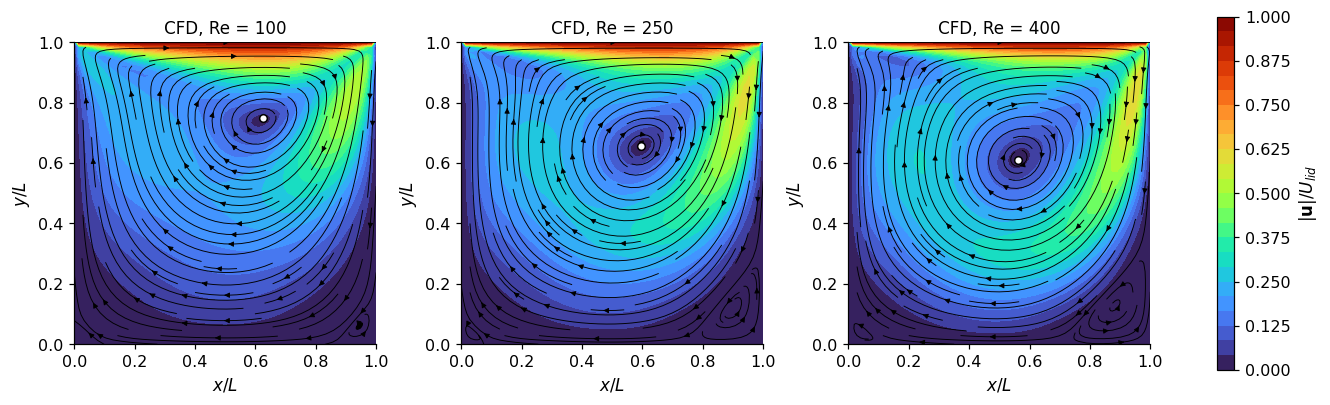

In [2]:
targets = primary_targets(data)
names = ["psi_min", "vortex_x", "vortex_y"]
display(pd.DataFrame({"Re": data["Re"], "role": roles,
                      **{name: targets[:, j] for j, name in enumerate(names)}}))
selected_fit = np.flatnonzero(fit)[[0, len(np.flatnonzero(fit))//2, -1]]
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
max_speed = max(np.hypot(data["u"][k], data["v"][k]).max() for k in selected_fit)
levels = np.linspace(0, max_speed, 25)
for ax, k in zip(axes, selected_fit):
    image = ax.contourf(data["x"], data["y"], np.hypot(data["u"][k], data["v"][k]),
                       levels=levels, cmap="turbo")
    ax.streamplot(data["x"], data["y"], data["u"][k], data["v"][k],
                  color="black", density=1.2, linewidth=.6, arrowsize=.7)
    ax.plot(targets[k, 1], targets[k, 2], "wo", mec="black", ms=5)
    ax.set(title=f"CFD, Re = {data['Re'][k]:g}", xlabel=r"$x/L$", ylabel=r"$y/L$",
           aspect="equal", xlim=(0, 1), ylim=(0, 1))
fig.colorbar(image, ax=axes, shrink=.82, label=r"$|\mathbf{u}|/U_{lid}$")
save_figure(fig, OUT, "fitting_cfd_fields")
plt.show()

## 3. Linear-interpolation baseline

For a requested Reynolds number $R$ between fitting cases $R_a<R<R_b$, use

$$\widehat q(R)=(1-w)q(R_a)+wq(R_b),\qquad w=\frac{R-R_a}{R_b-R_a}.$$

No optimizer is needed. This baseline is competitive when the mapping varies
smoothly. It cannot safely extrapolate beyond its bracketing cases; the implementation
raises an error instead. The same formula will later interpolate every velocity
component at each grid location. It does not solve the Navier–Stokes equations.

In [3]:
def scalar_interpolation(reynolds):
    return np.vstack([interpolate_rows(r, data["Re"][fit], targets[fit]) for r in reynolds])
dense_re = np.linspace(data["Re"][fit].min(), data["Re"][fit].max(), 201)
interpolation_dense = scalar_interpolation(dense_re)
print("Interpolation is fixed from", int(fit.sum()), "complete fitting cases.")

Interpolation is fixed from 6 complete fitting cases.


## 4. Polynomial baseline

Fit a quadratic map $\widehat q(R)=a_0+a_1R+a_2R^2$ independently for each of the
three outputs by least squares. `PolynomialFeatures` constructs the basis;
`StandardScaler` scales its columns using fitting Re values only; linear regression
then determines the coefficients. A polynomial is a global regression, unlike the
local bracketing rule. Its smooth curve may miss a grid-quantized vortex position,
and raising the degree can produce oscillation with so few independent cases.

In [4]:
POLYNOMIAL_DEGREE = 2
poly = make_pipeline(PolynomialFeatures(POLYNOMIAL_DEGREE), StandardScaler(), LinearRegression())
poly.fit(data["Re"][fit, None], targets[fit])
polynomial_dense = poly.predict(dense_re[:, None])
print("Polynomial degree:", POLYNOMIAL_DEGREE)

Polynomial degree: 2


## 5. Compact scalar DNN: three independent seeds

The network has one normalized Re input, two hidden layers of 32 tanh units, and
three linear outputs. A dense layer computes $h_{\ell+1}=\tanh(W_\ell h_\ell+b_\ell)$;
the last layer has no activation because the target components have different
signs and ranges. Use fitting-only means and standard deviations to scale the
targets. Otherwise the larger numerical component could dominate the loss.

We minimize component MSE with Adam, then use full-batch L-BFGS as a deterministic
refinement of the **same** loss. This connects to Week 1.3: Adam adapts componentwise
step sizes, while L-BFGS uses curvature information from recent gradient changes.
The lowest validation-loss checkpoint is restored. Three seeds change initialization,
not the data split. Their standard deviation is initialization sensitivity; it is
not a calibrated confidence interval and does not account for CFD/grid error.

The scalar loss below is MSE in standardized target coordinates; the later field
loss is MSE of velocity components normalized by lid speed. Their raw numerical
values have different meanings. The star marks the restored validation checkpoint,
which may precede the final training iteration.

Edit `SCALAR_WIDTHS`, `ACTIVATION`, or the training budgets below, using validation
results to make choices. Select a final design before running the test section.

Seed 11 selected: {'validation': 0.044576106606045864, 'stage': 'Adam', 'step': 180} | seconds: 0.57


Seed 22 selected: {'validation': 0.04807045746037725, 'stage': 'Adam', 'step': 180} | seconds: 0.65


Seed 33 selected: {'validation': 0.045755804196730816, 'stage': 'Adam', 'step': 240} | seconds: 0.5


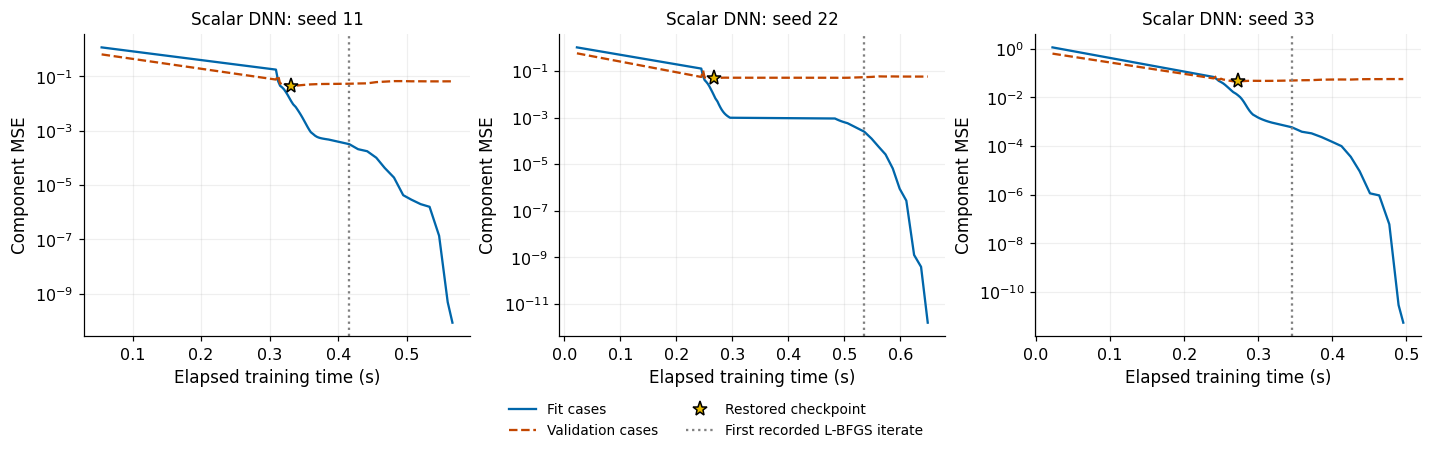

In [5]:
SCALAR_WIDTHS = (32, 32)
ACTIVATION = "tanh"
SCALAR_SEEDS = (11, 22, 33)
rmin, rmax = data["Re"][fit].min(), data["Re"][fit].max()
scale_r = lambda r: 2*(np.asarray(r)-rmin)/(rmax-rmin)-1
qmean = targets[fit].mean(axis=0)
qstd = targets[fit].std(axis=0)
qstd = np.where(qstd > 1e-12, qstd, 1.0)
scalar_models, scalar_histories, scalar_metadata = [], {}, []
for seed in SCALAR_SEEDS:
    cfg = NetworkConfig(widths=SCALAR_WIDTHS, activation=ACTIVATION,
                        adam_steps=600, lbfgs_steps=250, seed=seed)
    model, history, meta = fit_network(
        scale_r(data["Re"][fit, None]), (targets[fit]-qmean)/qstd,
        scale_r(data["Re"][validation, None]), (targets[validation]-qmean)/qstd, cfg)
    scalar_models.append(model); scalar_histories[f"Scalar DNN: seed {seed}"] = history
    scalar_metadata.append(meta)
    print("Seed", seed, "selected:", meta["selected"], "| seconds:", round(meta["seconds"], 2))
scalar_dense_by_seed = np.stack([np.asarray(model(scale_r(dense_re[:, None]))) * qstd + qmean
                                 for model in scalar_models])
fig = plot_histories(scalar_histories)
save_figure(fig, OUT, "scalar_losses"); plt.show()

## 6. Full-field interpolation baseline

Apply the same bracketing rule to the **u and v arrays**, keeping the native grid and
the wall convention. Because both parent fields have identical wall values, their
linear interpolant preserves those values. The finite-difference divergence operator
is linear, so interpolation also inherits the divergence properties of the parent
fields. Neither fact guarantees a momentum-equation solution at the new Re.

The next section fits coordinate networks using precisely the same fit/validation
cases. After both models are frozen, we will plot interpolation alongside the neural
fields at every test Re, rather than allowing a scalar error table to replace a
physical comparison.

In [6]:
def interpolate_field(reynolds):
    return tuple(interpolate_rows(reynolds, data["Re"][fit], data[name][fit]) for name in ("u", "v"))
print("Field interpolation prepared; no test scores inspected yet.")

Field interpolation prepared; no test scores inspected yet.


## 7. Coordinate DNNs: (Re, x, y) to (u, v)

A coordinate network receives a normalized Re and two positions, and predicts the
two velocity components. Unlike the scalar DNN it must represent a spatially varying
vector field and thin wall gradients. The inputs do not by themselves enforce any
boundary condition or conservation law. A low average MSE can coexist with substantial
wall leakage because the wall occupies a small fraction of the samples.

We compare **two networks with identical hidden-layer widths, activation, seed,
training points, optimizers, and iteration budgets**. The raw model has two direct
outputs. The boundary-aware model uses the same neural outputs $N_u,N_v$ inside a
known boundary construction:

$$s=x(1-x),\quad d=s^2+(1-y)^2,\quad
g(x,y)=\frac{ys^2}{d},\quad e(x,y)=\frac{4ys(1-y)}{d},$$
$$\widehat u=g+eN_u,\qquad \widehat v=eN_v.$$

At the two top corners set $g=0$ using a safe zero-denominator operation. On the
open lid $g=1$, while $g=0$ on the stationary walls and $e=0$ on every wall. Thus
no-slip values are enforced by the model definition, not by editing the predicted
plot. This is a **supervised model with prescribed boundaries**, not a PINN: no
momentum or divergence residual is in its loss. Exact walls do not ensure a correct
interior vortex. The discontinuous corner convention is part of this benchmark.

**Why the boundary construction matters.** A tempting alternative uses
$g_{old}=ys/[s+(1-y)^2]$ and $e_{old}=16sy(1-y)$. Near a top corner, along
$x\approx1-y\approx h$, its lifting approaches one while its envelope is of order
$h^2$. The network must then produce a large correction divided by a tiny envelope.
The corner-compatible construction above has both lifting and envelope of order
one along that diagonal, while retaining exact wall values. This improves the
conditioning of the learning problem; it does not add a momentum equation.
`BOUNDARY_LIFTING="product"` reproduces the alternative for an explicit ablation.

The fitting sampler uses every second node plus all wall-adjacent rows and columns;
validation uses the complete native grids. Both models minimize ordinary unweighted
velocity-component MSE. Full-batch training keeps the optimizer comparison free of
minibatch sampling changes. The loss plot and physical diagnostics decide whether
the extra boundary knowledge helped under this finite CPU budget.

The L-BFGS budget is a maximum number of **accepted iterations**, not an equal
number of objective/gradient evaluations: line searches can evaluate several trial
steps. The output metadata records `nit`, function/gradient calls and elapsed time.
Use those costs when comparing optimization efficiency.

Coordinate DNN | parameters: 4994 | selected: {'validation': 1.6431442687965697e-05, 'stage': 'L-BFGS', 'step': 2400} | seconds: 17.99


Boundary-aware DNN | parameters: 4994 | selected: {'validation': 1.697504554861759e-05, 'stage': 'L-BFGS', 'step': 2400} | seconds: 18.66


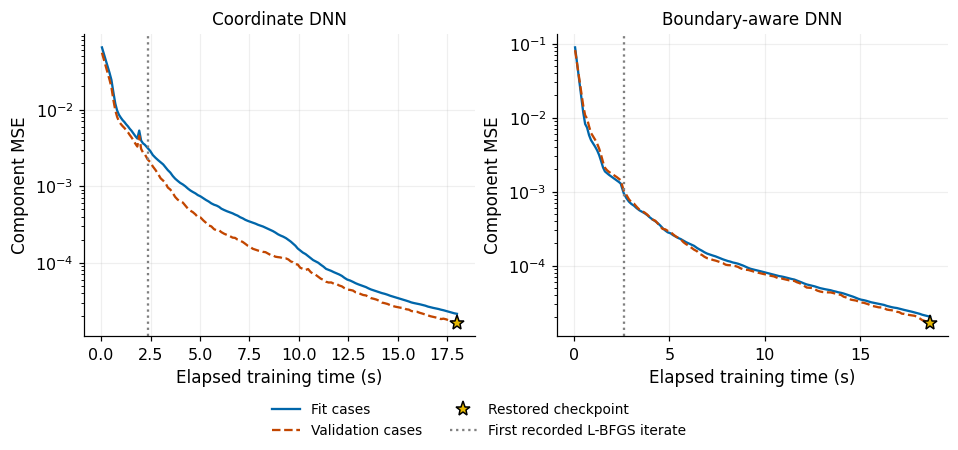

In [7]:
FIELD_WIDTHS = (48, 48, 48)
BOUNDARY_LIFTING = "corner"  # "product" reproduces the retained boundary ablation.
FIELD_ADAM_STEPS = 400
FIELD_LBFGS_STEPS = 2400
TRAIN_STRIDE = 2
Xtr, Qtr = point_samples(data, fit, rmin, rmax, stride=TRAIN_STRIDE)
Xval, Qval = point_samples(data, validation, rmin, rmax, stride=1)
field_models, field_histories, field_metadata = {}, {}, {}
for name, boundary_aware in [("Coordinate DNN", False), ("Boundary-aware DNN", True)]:
    cfg = NetworkConfig(widths=FIELD_WIDTHS, activation=ACTIVATION,
                        adam_steps=FIELD_ADAM_STEPS, lbfgs_steps=FIELD_LBFGS_STEPS,
                        boundary_aware=boundary_aware, boundary_lifting=BOUNDARY_LIFTING, seed=690)
    model, history, meta = fit_network(Xtr, Qtr, Xval, Qval, cfg)
    field_models[name] = model; field_histories[name] = history; field_metadata[name] = meta
    print(name, "| parameters:", meta["parameters"], "| selected:", meta["selected"],
          "| seconds:", round(meta["seconds"], 2))
fig = plot_histories(field_histories)
save_figure(fig, OUT, "field_losses"); plt.show()

## 8. Freeze the fitted models, then evaluate every test case

The next cell records the split, data checksum, model configuration, selected
validation checkpoint and all frozen weights. From this point onward the test data
are used only for evaluation and figures. If a model loses to interpolation, report
that result. Larger networks and longer training are experiments, not guaranteed
improvements; another round of development requires a new independent final test.

In [8]:
frozen = {"data_sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
          "helper_source_sha256": hashlib.sha256((ROOT / "flowmllab/cavity_lab2.py").read_bytes()).hexdigest(),
          "packages": {name: importlib.metadata.version(name) for name in ("numpy", "scipy", "keras")},
          "tensorflow": tf.__version__,
          "fit_Re": data["Re"][fit].tolist(), "validation_Re": data["Re"][validation].tolist(),
          "test_Re": data["Re"][test].tolist(), "rmin": float(rmin), "rmax": float(rmax),
          "target_mean": qmean.tolist(), "target_std": qstd.tolist(),
          "scalar_models": scalar_metadata, "field_models": field_metadata,
          "training_points": int(len(Xtr)), "validation_points": int(len(Xval)),
          "corner_metric_regions": "Native interior nodes within 0.2 L of both adjoining walls; wall nodes excluded.",
          "test_labels_used_in_fitting_or_selection": False,
          "public_test_previously_inspected": True,
          "independent_blind_research_test": False}
(OUT / "frozen_models.json").write_text(json.dumps(frozen, indent=2), encoding="utf-8")
weights = {}
for label, model in [(f"scalar_seed{seed}", model) for seed, model in zip(SCALAR_SEEDS, scalar_models)] + list(field_models.items()):
    for j, w in enumerate(model.get_weights()): weights[f"{label.replace(' ', '_')}_{j}"] = w
np.savez_compressed(OUT / "frozen_weights.npz", **weights)
(OUT / "training_histories.json").write_text(json.dumps({**scalar_histories, **field_histories}, indent=2))
print("Frozen model weights and split recorded before test evaluation.")

Frozen model weights and split recorded before test evaluation.


,method,Re,CFD_psi_min,CFD_vortex_x,CFD_vortex_y,predicted_psi_min,predicted_vortex_x,predicted_vortex_y
0,Interpolation,175.0,-0.104309,0.62500,0.687500,-0.104165,0.617188,0.687500
1,Interpolation,275.0,-0.106427,0.59375,0.640625,-0.106413,0.585938,0.648438
2,Interpolation,375.0,-0.107441,0.56250,0.625000,-0.107347,0.566406,0.617188
3,Quadratic,175.0,-0.104309,0.62500,0.687500,-0.104207,0.612500,0.692773
4,Quadratic,275.0,-0.106427,0.59375,0.640625,-0.106457,0.589286,0.642997
5,Quadratic,375.0,-0.107441,0.56250,0.625000,-0.107467,0.566071,0.615541
6,DNN ensemble,175.0,-0.104309,0.62500,0.687500,-0.104125,0.614037,0.692443
7,DNN ensemble,275.0,-0.106427,0.59375,0.640625,-0.106392,0.587550,0.644955
8,DNN ensemble,375.0,-0.107441,0.56250,0.625000,-0.107503,0.565455,0.615838


,Interpolation,Quadratic,DNN ensemble
Observable MAE,,,
psi_min,0.000084,0.000053,0.000094
vortex_x,0.006510,0.006845,0.006706
vortex_y,0.005208,0.005701,0.006145


,seed_std_psi_min,seed_std_vortex_x,seed_std_vortex_y
Re,,,
175.0,0.000050,0.000463,0.000642
275.0,0.000029,0.000392,0.000802
375.0,0.000025,0.000127,0.000337


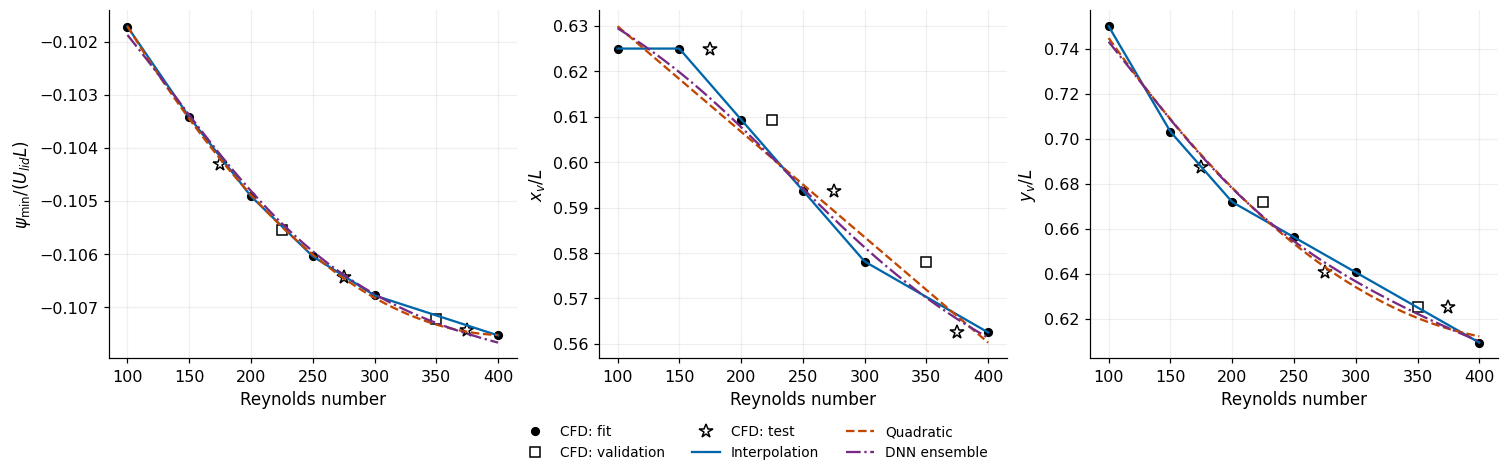

In [9]:
scalar_predictions = {"Interpolation": scalar_interpolation(data["Re"][test]),
                      "Quadratic": poly.predict(data["Re"][test, None])}
seed_preds = np.stack([np.asarray(model(scale_r(data["Re"][test, None]))) * qstd + qmean
                       for model in scalar_models])
scalar_predictions["DNN ensemble"] = seed_preds.mean(axis=0)
np.savez_compressed(OUT / "scalar_predictions.npz", Re=data["Re"], reference=targets, role=roles,
                    observable_names=np.asarray(names), dense_Re=dense_re,
                    interpolation_dense=interpolation_dense, polynomial_dense=polynomial_dense,
                    neural_dense_by_seed=scalar_dense_by_seed, seeds=np.asarray(SCALAR_SEEDS),
                    test_Re=data["Re"][test], neural_test_by_seed=seed_preds)
rows = []
for method, predictions in scalar_predictions.items():
    for k, reynolds in enumerate(data["Re"][test]):
        rows.append({"method": method, "Re": float(reynolds),
                     **{f"CFD_{n}": float(targets[test][k, j]) for j, n in enumerate(names)},
                     **{f"predicted_{n}": float(predictions[k, j]) for j, n in enumerate(names)}})
scalar_table = pd.DataFrame(rows)
scalar_table.to_csv(OUT / "week4_scalar_results.csv", index=False)
display(scalar_table)
scalar_errors = pd.DataFrame({method: np.mean(np.abs(pred-targets[test]), axis=0)
                              for method, pred in scalar_predictions.items()}, index=names)
display(scalar_errors.rename_axis("Observable MAE"))
display(pd.DataFrame(seed_preds.std(axis=0), columns=[f"seed_std_{n}" for n in names],
                     index=data["Re"][test]).rename_axis("Re"))
fig = plot_scalar_trends(data["Re"], targets, fit, validation, test, dense_re,
                         {"Interpolation": interpolation_dense, "Quadratic": polynomial_dense,
                          "DNN ensemble": scalar_dense_by_seed.mean(axis=0)})
save_figure(fig, OUT, "scalar_trends"); plt.show()

### Reading the scalar comparison

Read **all three observable panels**. A method can predict streamfunction strength
well and still miss a grid-quantized vortex coordinate. Compare open test stars with
each method curve. The interpolation and quadratic controls can beat the DNN with
this small smooth dataset; neural complexity is not evidence of accuracy. Compare
each seed's error with its spread and avoid calling three seeds a confidence bound.

In [10]:
test_predictions, metrics_rows, native = {}, [], {"x": data["x"], "y": data["y"], "Re": data["Re"][test]}
for index in np.flatnonzero(test):
    reynolds = float(data["Re"][index])
    predictions = {"Interpolation": interpolate_field(reynolds)}
    predictions.update({name: predict_field(model, reynolds, data, rmin, rmax)
                        for name, model in field_models.items()})
    test_predictions[index] = predictions
    native[f"Re{reynolds:g}_CFD_u"] = data["u"][index]
    native[f"Re{reynolds:g}_CFD_v"] = data["v"][index]
    for name, (up, vp) in predictions.items():
        metrics_rows.append({"Re": reynolds, "method": name,
                             **field_metrics(data["x"], data["y"], data["u"][index], data["v"][index], up, vp)})
        native[f"Re{reynolds:g}_{name.replace(' ', '_')}_u"] = up
        native[f"Re{reynolds:g}_{name.replace(' ', '_')}_v"] = vp
field_table = pd.DataFrame(metrics_rows)
field_table.to_csv(OUT / "field_metrics.csv", index=False)
np.savez_compressed(OUT / "native_test_predictions.npz", **native)
display(field_table[["Re", "method", "vector_relative_l2", "vector_rms", "vector_max", "wall_max"]])
display(field_table[["Re", "method", "divergence_core_rms", "reference_divergence_core_rms",
                     "upper_left_rms", "upper_right_rms", "lower_left_rms", "lower_right_rms"]])

,Re,method,vector_relative_l2,vector_rms,vector_max,wall_max
0,175.0,Interpolation,0.004644,0.001276,0.003905,0.000000
1,175.0,Coordinate DNN,0.019032,0.005228,0.030599,0.030599
2,175.0,Boundary-aware DNN,0.018328,0.005034,0.060391,0.000000
3,275.0,Interpolation,0.002116,0.000591,0.001824,0.000000
4,275.0,Coordinate DNN,0.019858,0.005542,0.034499,0.034499
5,275.0,Boundary-aware DNN,0.019103,0.005331,0.045570,0.000000
6,375.0,Interpolation,0.004339,0.001220,0.003391,0.000000
7,375.0,Coordinate DNN,0.024268,0.006826,0.038536,0.038536
8,375.0,Boundary-aware DNN,0.025451,0.007159,0.057782,0.000000


,Re,method,divergence_core_rms,reference_divergence_core_rms,upper_left_rms,upper_right_rms,lower_left_rms,lower_right_rms
0,175.0,Interpolation,4.071513e-16,2.423810e-16,0.000835,0.001491,0.000114,0.000023
1,175.0,Coordinate DNN,8.247064e-02,2.423810e-16,0.009201,0.008178,0.003061,0.002366
2,175.0,Boundary-aware DNN,8.529130e-02,2.423810e-16,0.011448,0.011051,0.001479,0.002035
3,275.0,Interpolation,4.344810e-16,2.273716e-16,0.000379,0.000489,0.000013,0.000045
4,275.0,Coordinate DNN,8.457110e-02,2.273716e-16,0.009978,0.008121,0.003359,0.002541
5,275.0,Boundary-aware DNN,1.006951e-01,2.273716e-16,0.012596,0.013414,0.002863,0.001980
6,375.0,Interpolation,5.197433e-16,2.155581e-16,0.000737,0.000853,0.000101,0.000048
7,375.0,Coordinate DNN,1.052714e-01,2.155581e-16,0.010566,0.011410,0.005000,0.003291
8,375.0,Boundary-aware DNN,1.160616e-01,2.155581e-16,0.016140,0.017586,0.005221,0.002752


## 9. Physical fields and error maps for every held-out Reynolds number

Each row of fields uses one speed scale spanning **all actual extrema** for the CFD,
interpolation and both neural methods at that Re. The lower error maps share one
linear scale and show vector error magnitude, $\sqrt{(\widehat u-u)^2+(\widehat v-v)^2}$.
This is an absolute error normalized by lid speed, not a pointwise relative error
that divides by near-zero velocity. The contour-overlay panel uses identical physical
speed levels. Distinct contours reveal agreement and displacement on the same axes.

Streamline geometry comes from each method's own u,v. It is not a pathline or a
solution-independent proof of a vortex. Thin secondary cells may be missed by
automatic seeding; centreline and near-wall profiles are therefore essential.
No smoothing or clipping is used to hide a poor prediction.

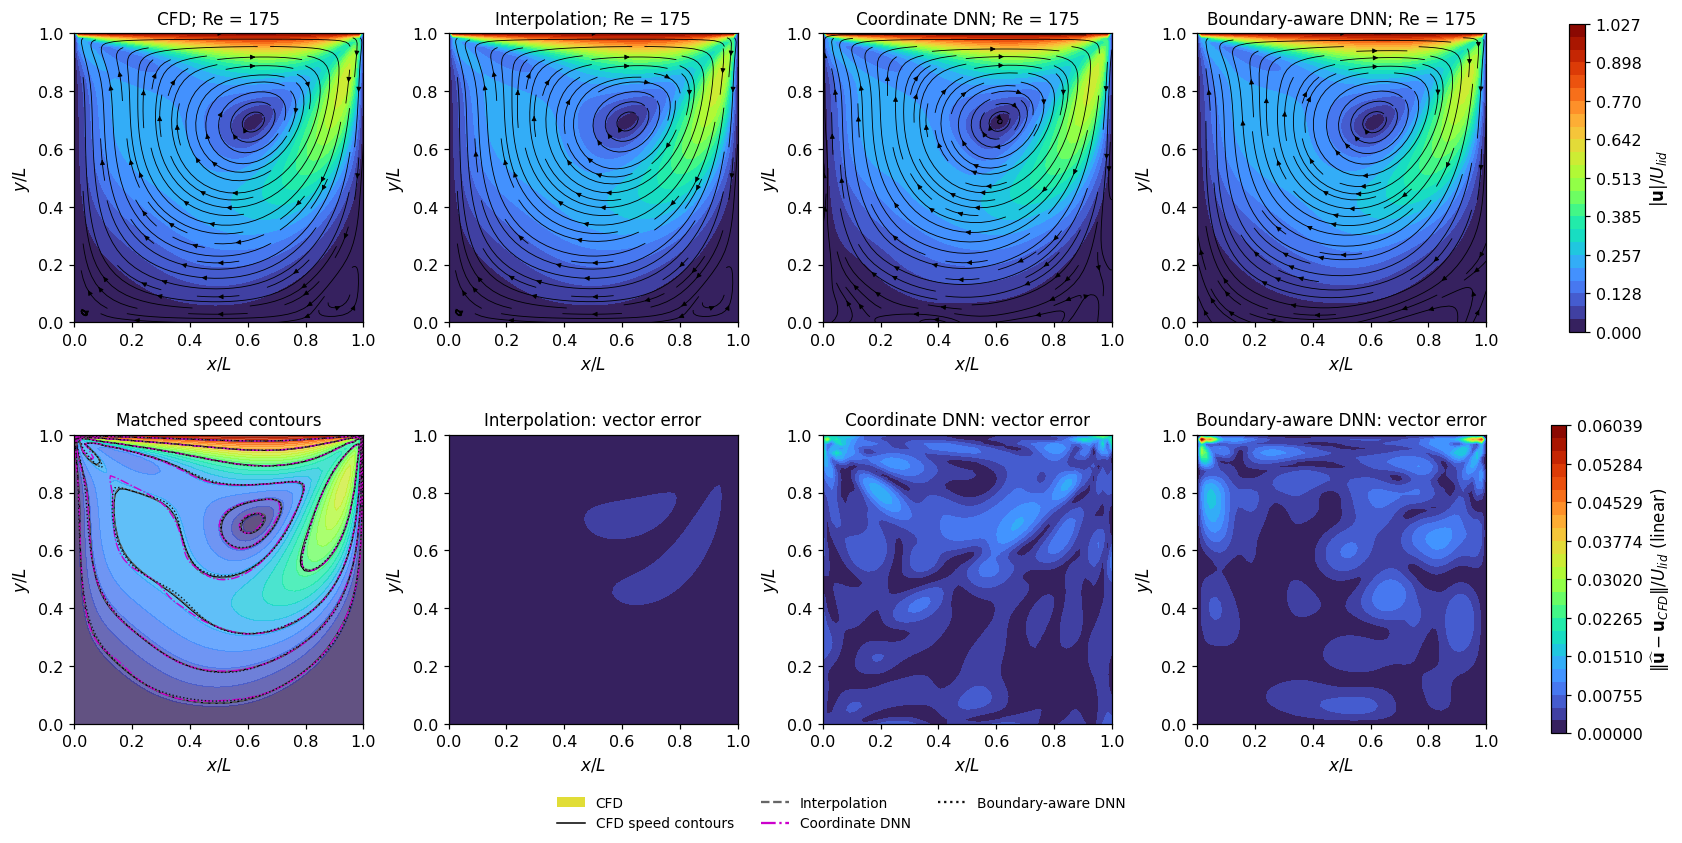

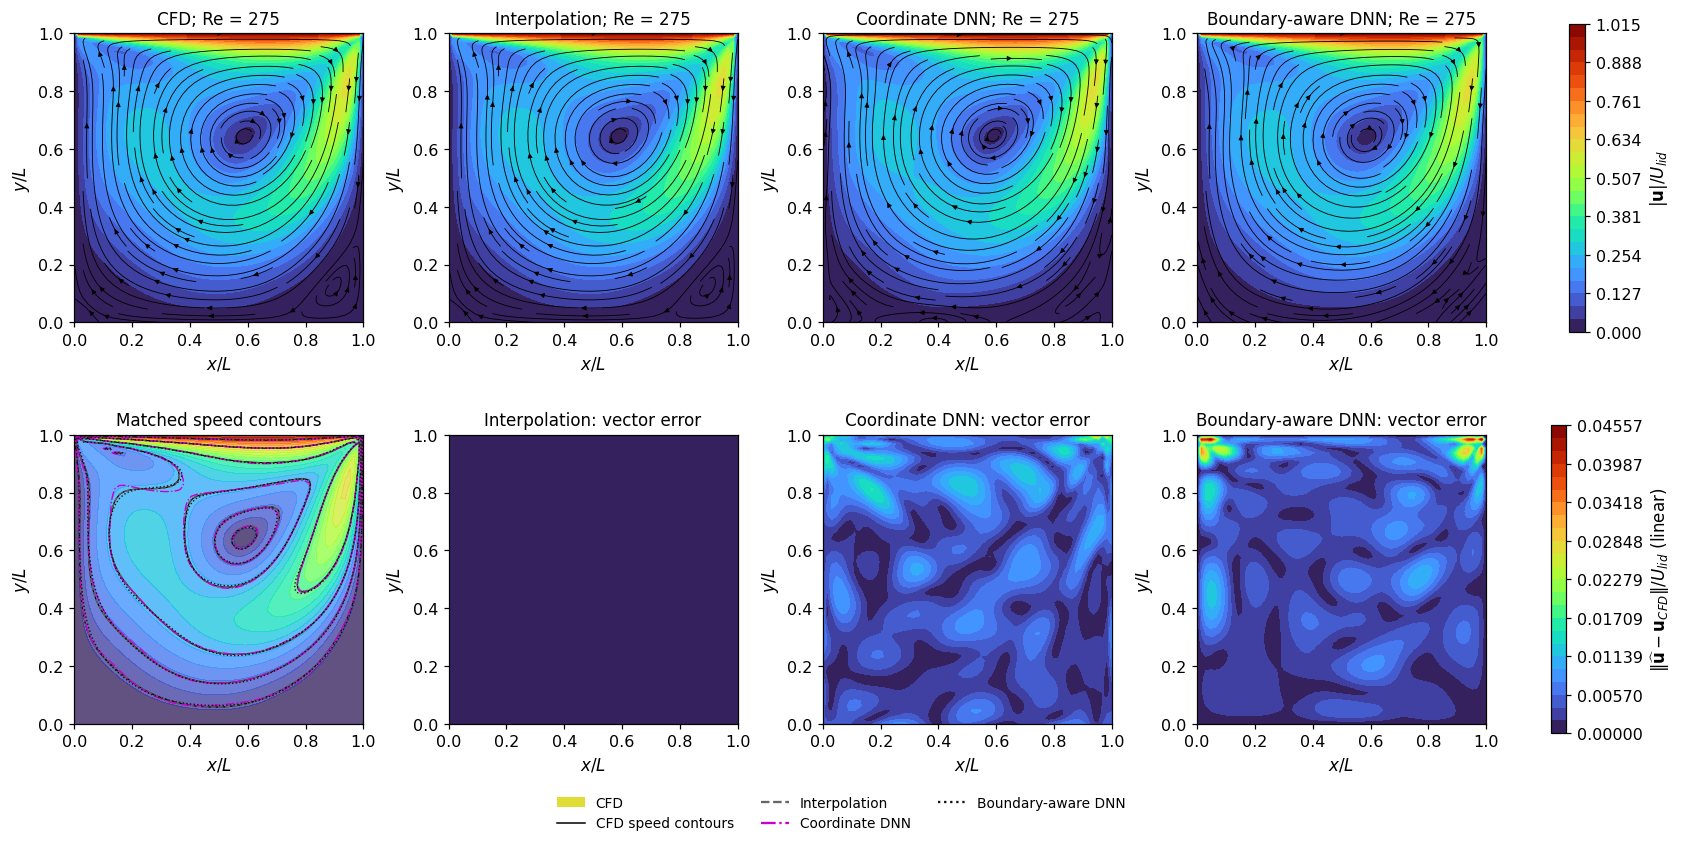

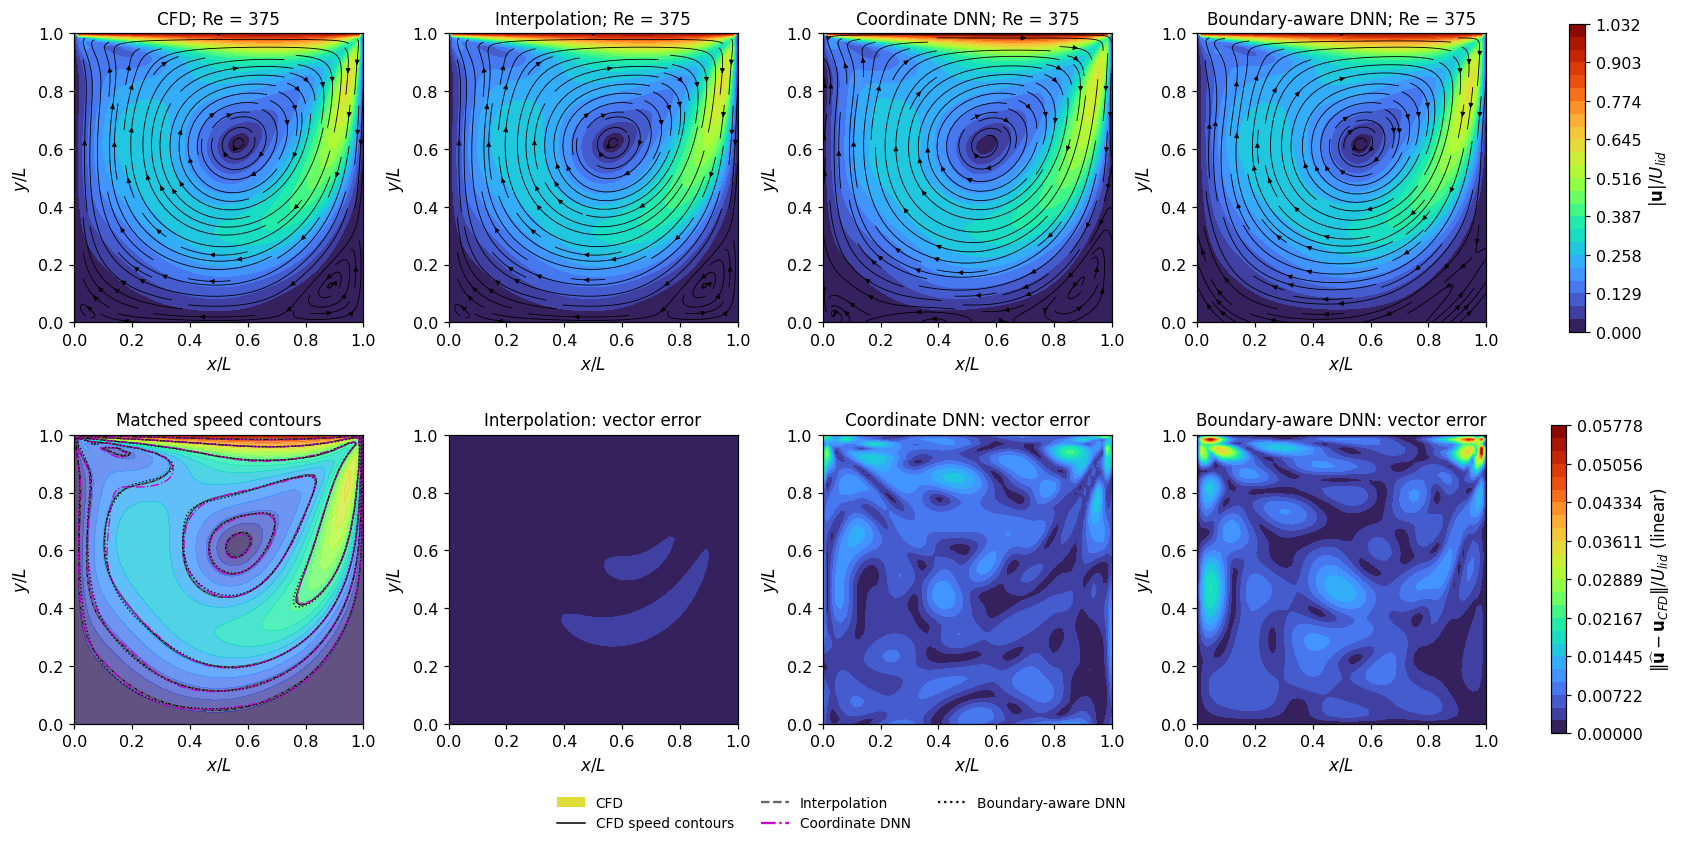

In [11]:
for index, predictions in test_predictions.items():
    fig = plot_field_comparison(data, index, predictions)
    save_figure(fig, OUT, f"field_re{data['Re'][index]:g}"); plt.show()

## 10. Centreline profiles and signed errors

Compare vertical-centreline u and horizontal-centreline v. The lower panels keep
the error sign, so overshoot and undershoot do not cancel invisibly. They also reveal
a small interior discrepancy when the full-domain colour scale is set by a corner
maximum. The comparisons are to the matched native-grid CFD cases. These Re values
are not Ghia table entries; do not attach an unrelated Ghia curve as ground truth.

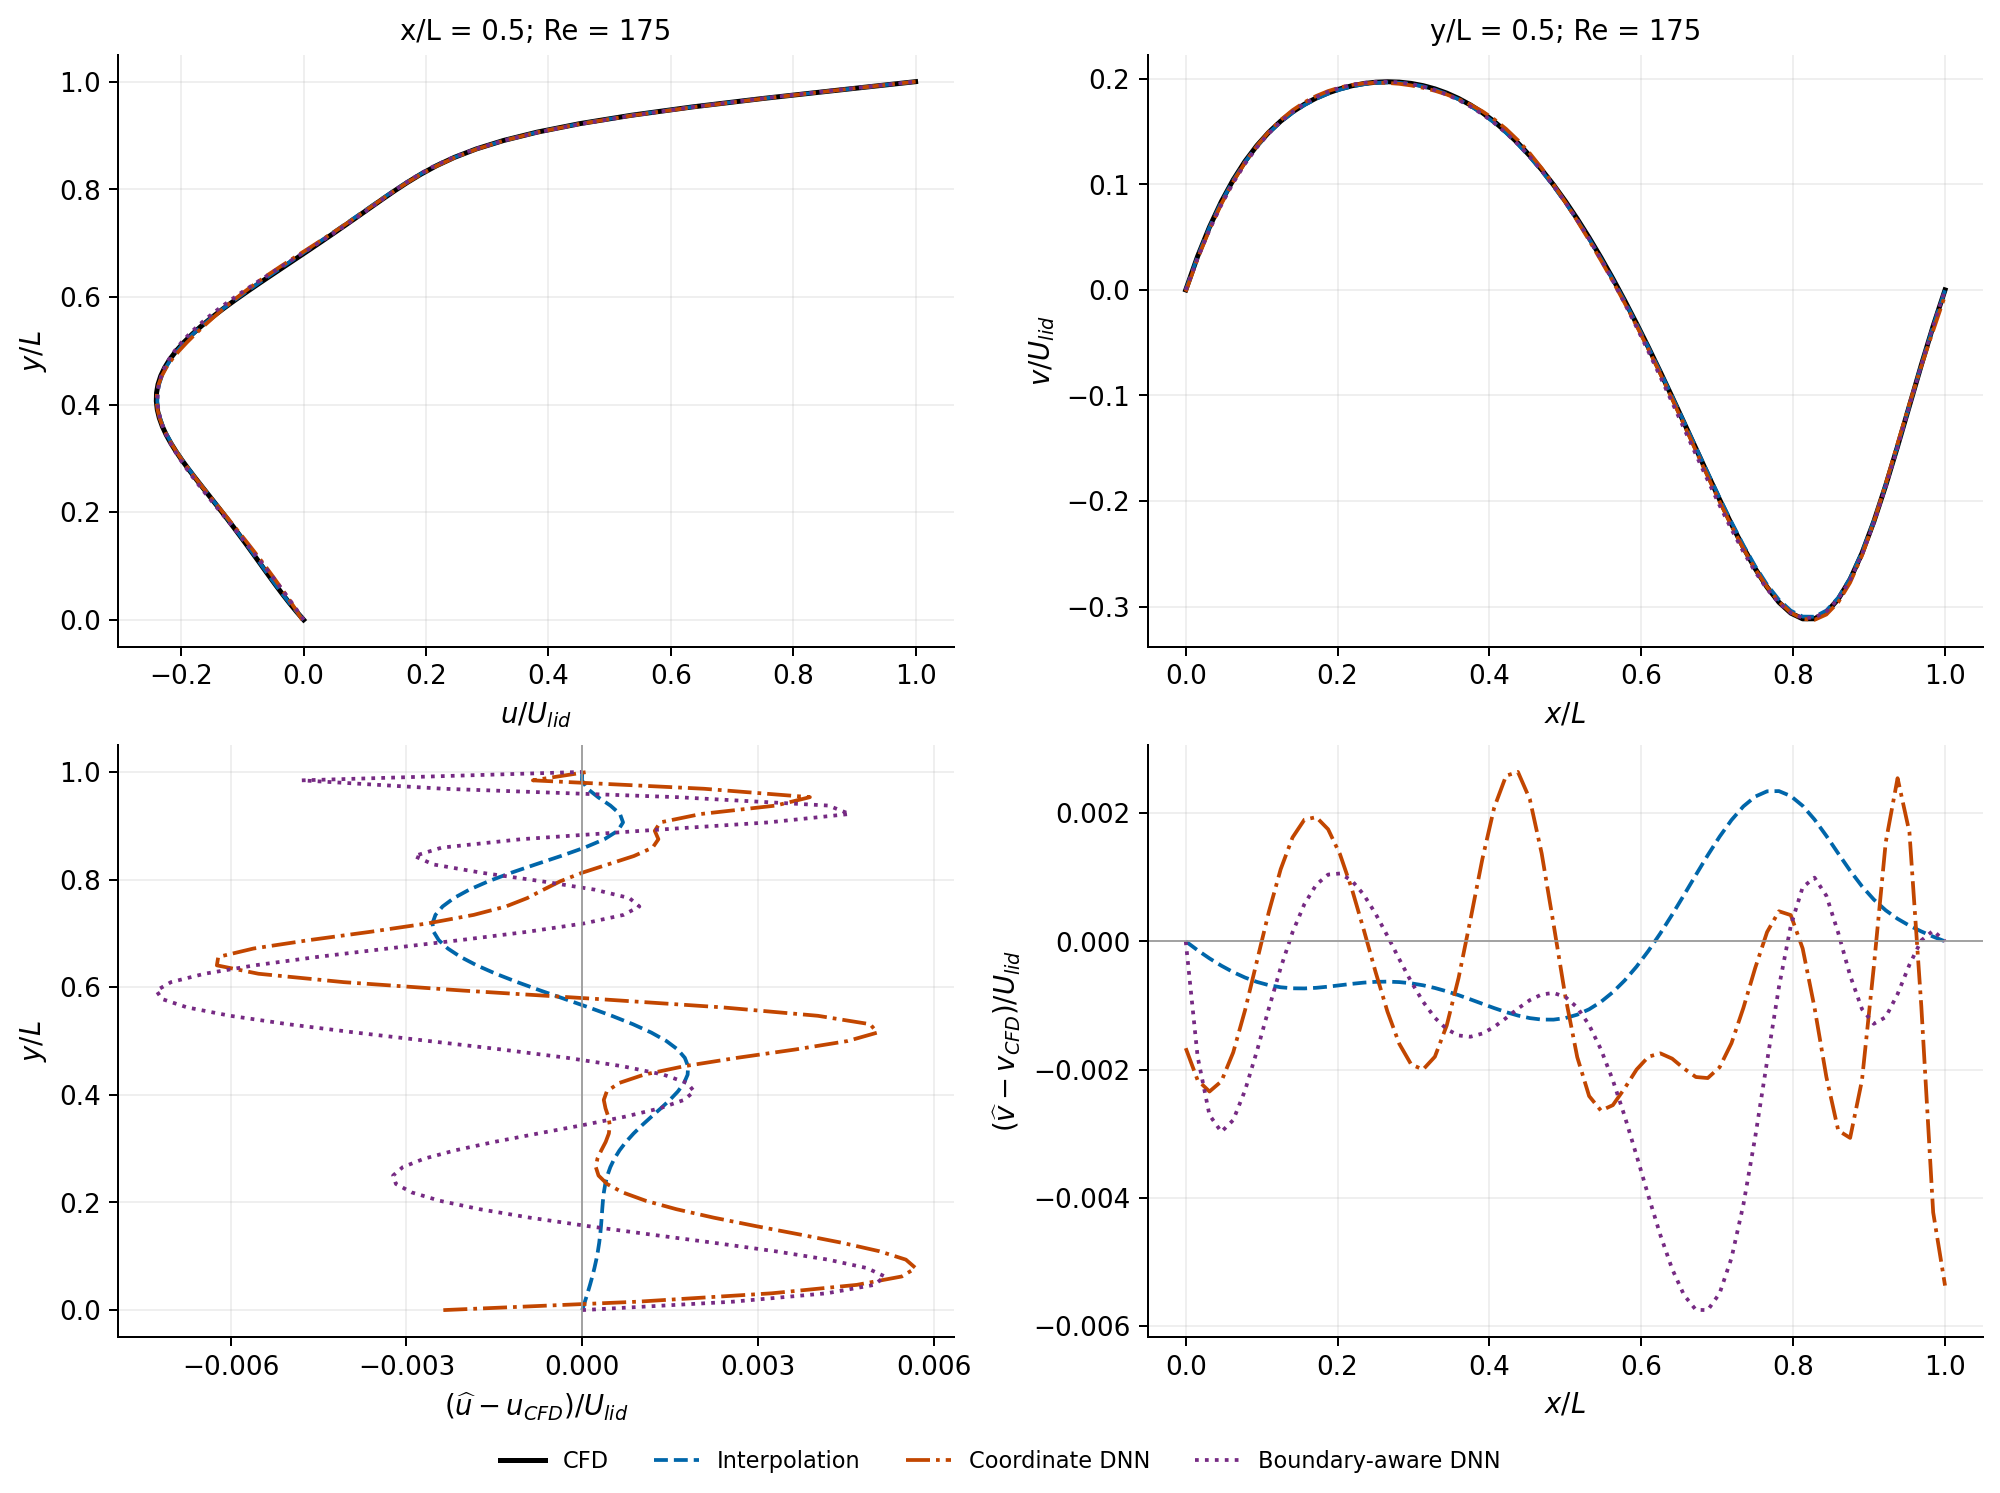

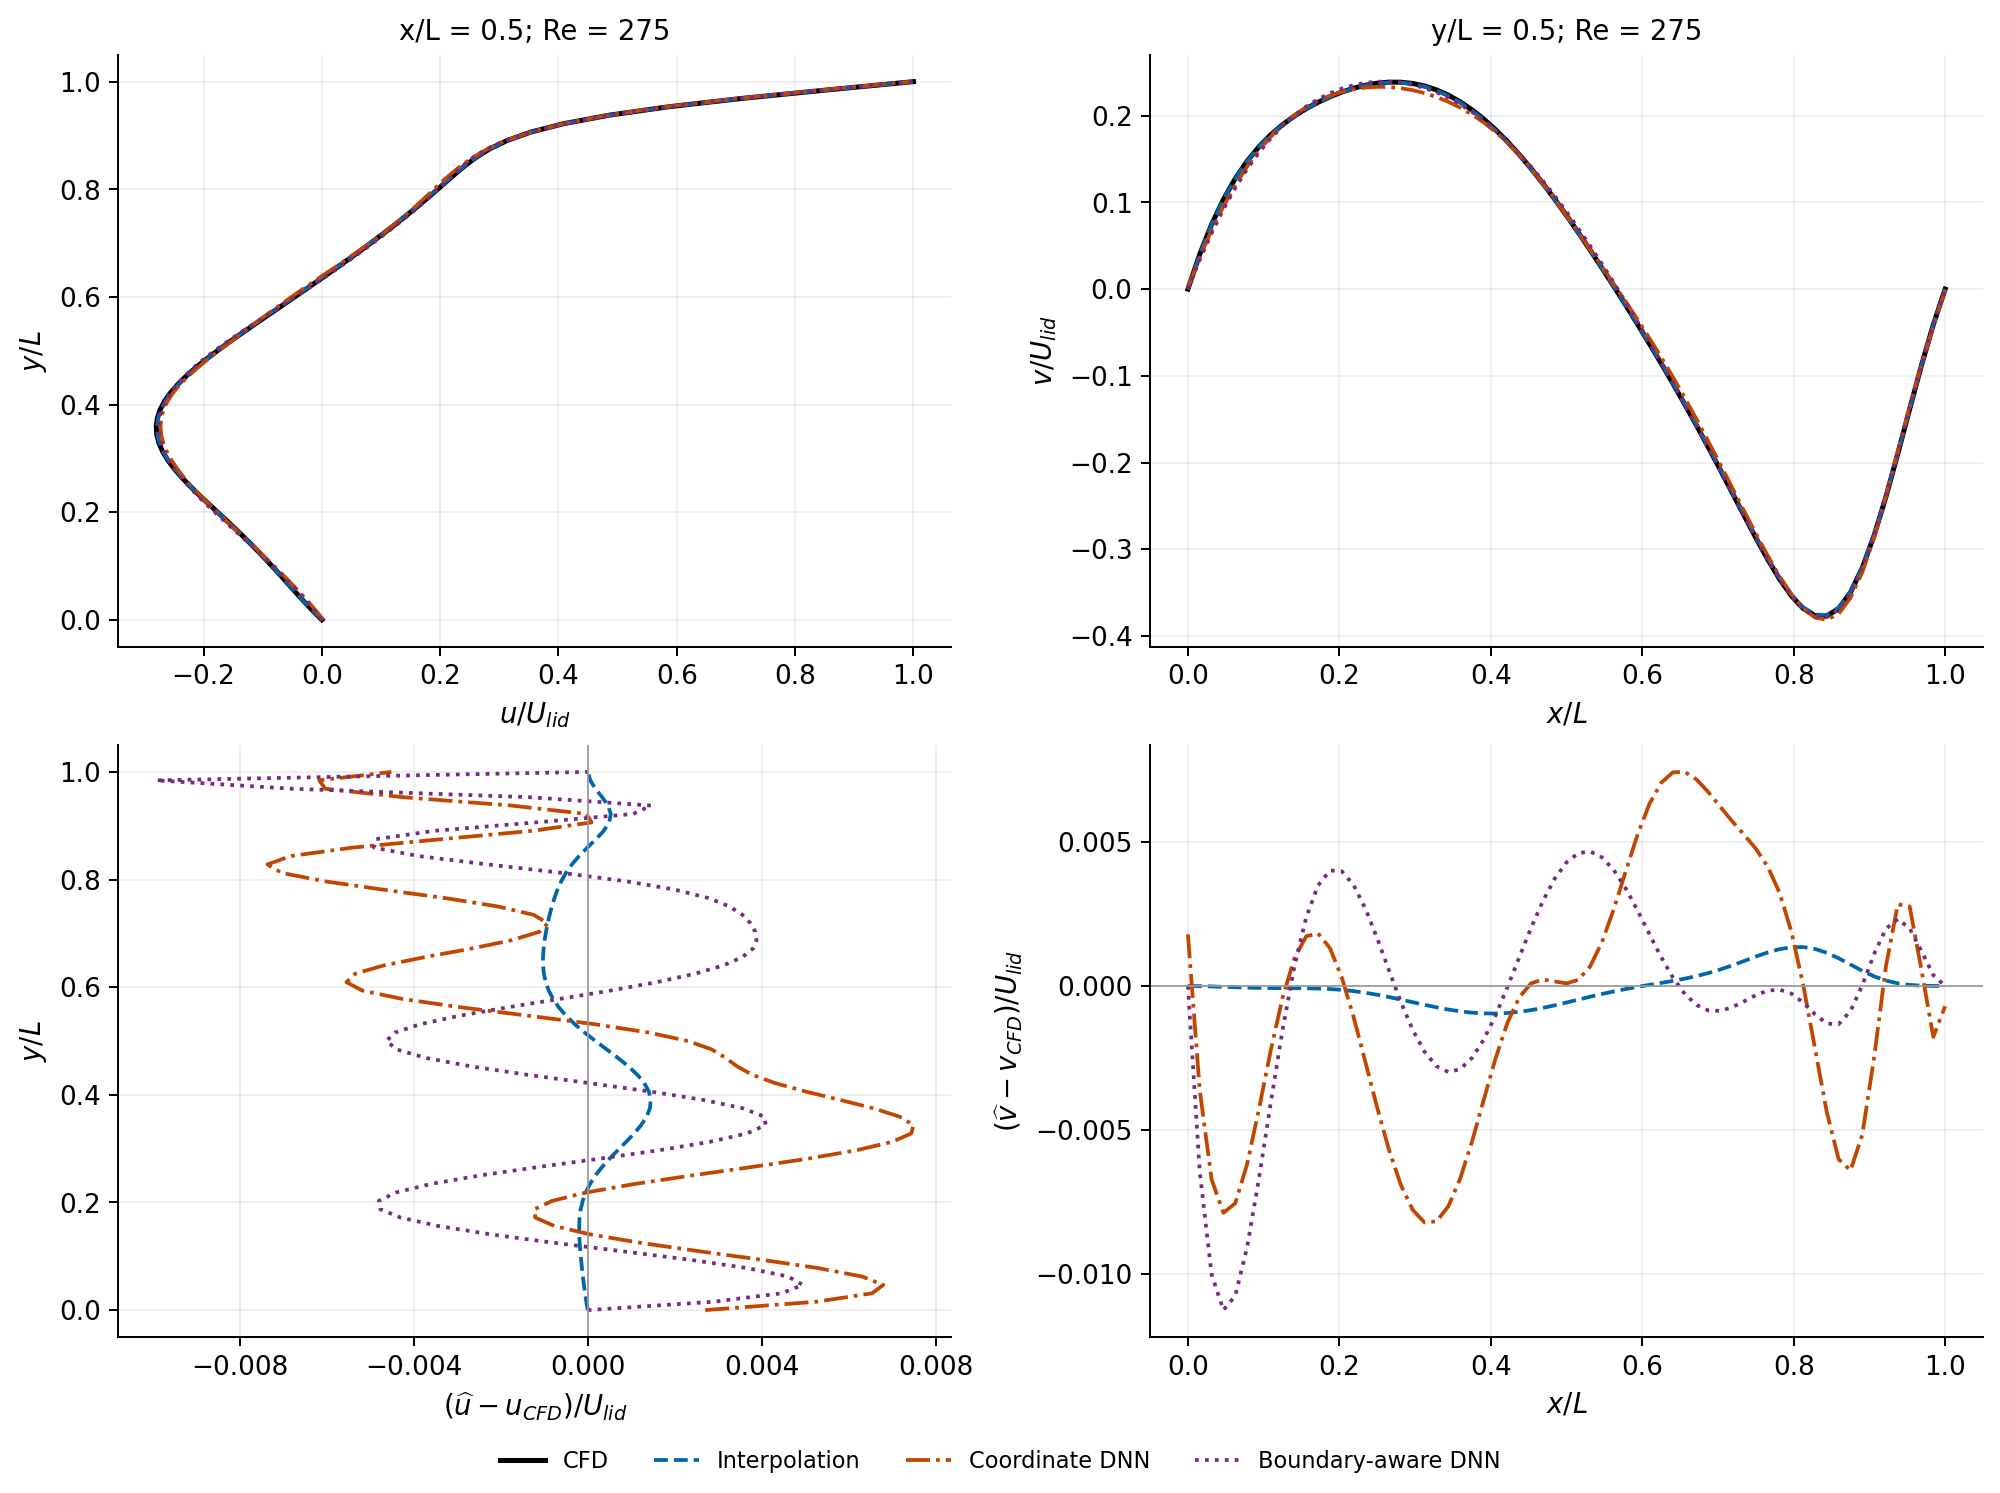

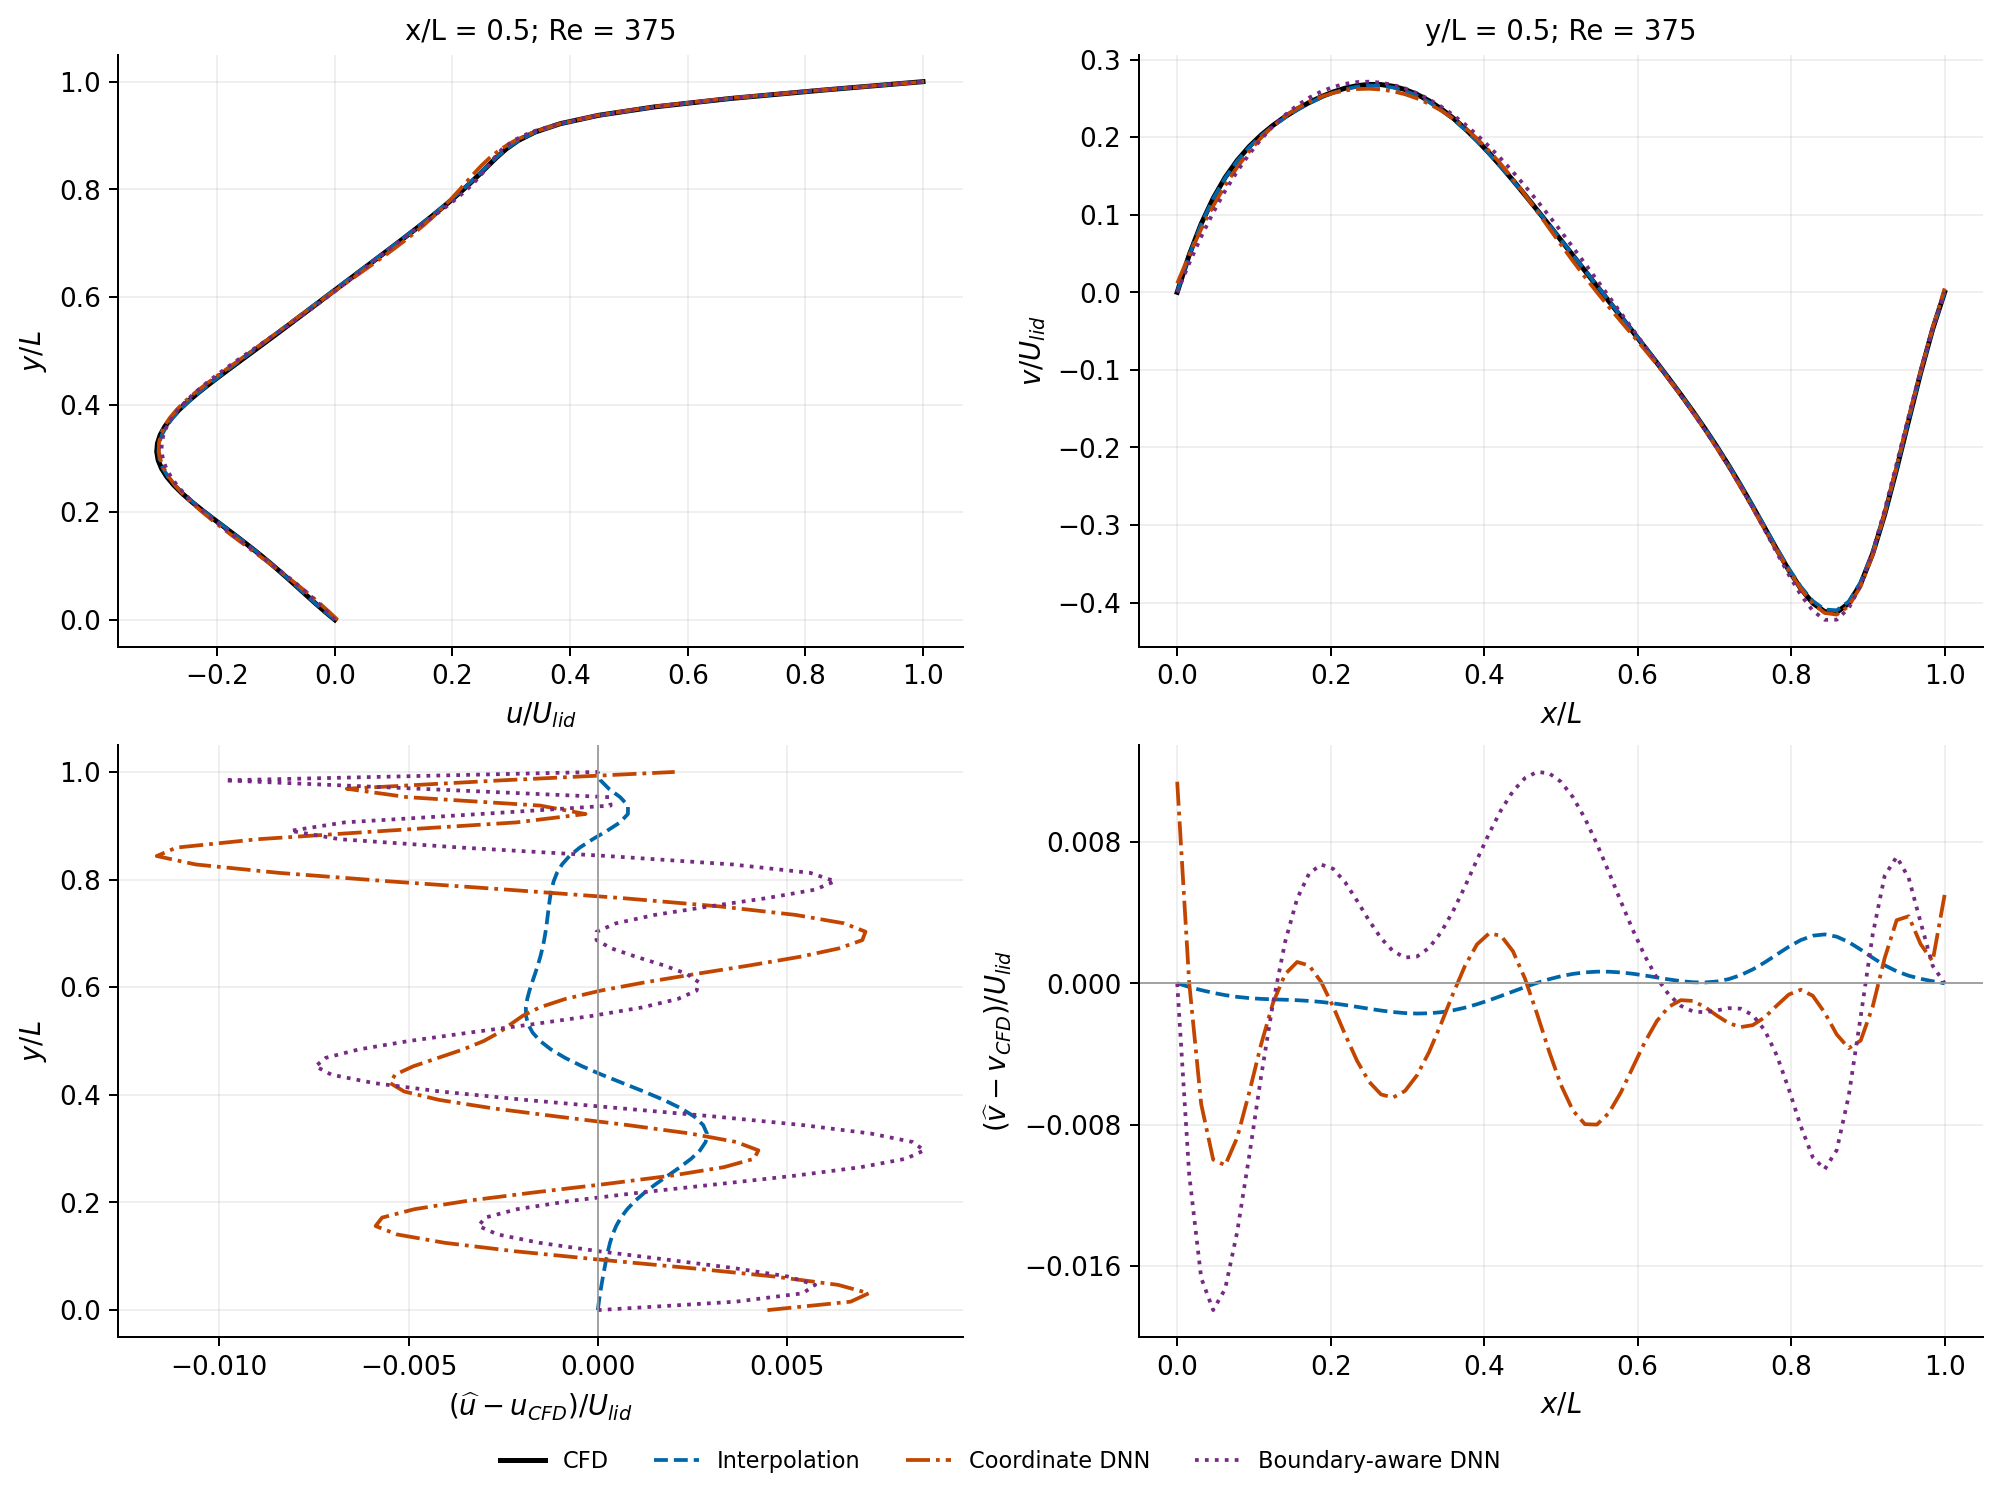

In [12]:
for index, predictions in test_predictions.items():
    fig = plot_profiles(data, index, predictions)
    save_figure(fig, OUT, f"profiles_re{data['Re'][index]:g}"); plt.show()

## 11. Wall error and incompressibility are separate diagnostics

The lid plot shows signed tangential-velocity error; the side-wall plot shows vector
error magnitude. The final plot differentiates the predicted native fields and shows
row-wise RMS divergence. A two-cell boundary rim is excluded and stated because the
discontinuous lid corners make derivative diagnostics particularly grid-sensitive.
The same calculation is applied to CFD. These are finite-difference diagnostics of
the sampled fields, not exact neural derivatives or a Navier–Stokes residual.

The boundary-aware network should have zero wall error up to arithmetic precision,
because its output formula enforces it. That is **not** evidence of zero interior
divergence, nor a guarantee of the correct main/secondary-vortex topology. Report a
failure wherever it remains. Full-field interpolation may be the most effective
surrogate in this small smooth Re interval.

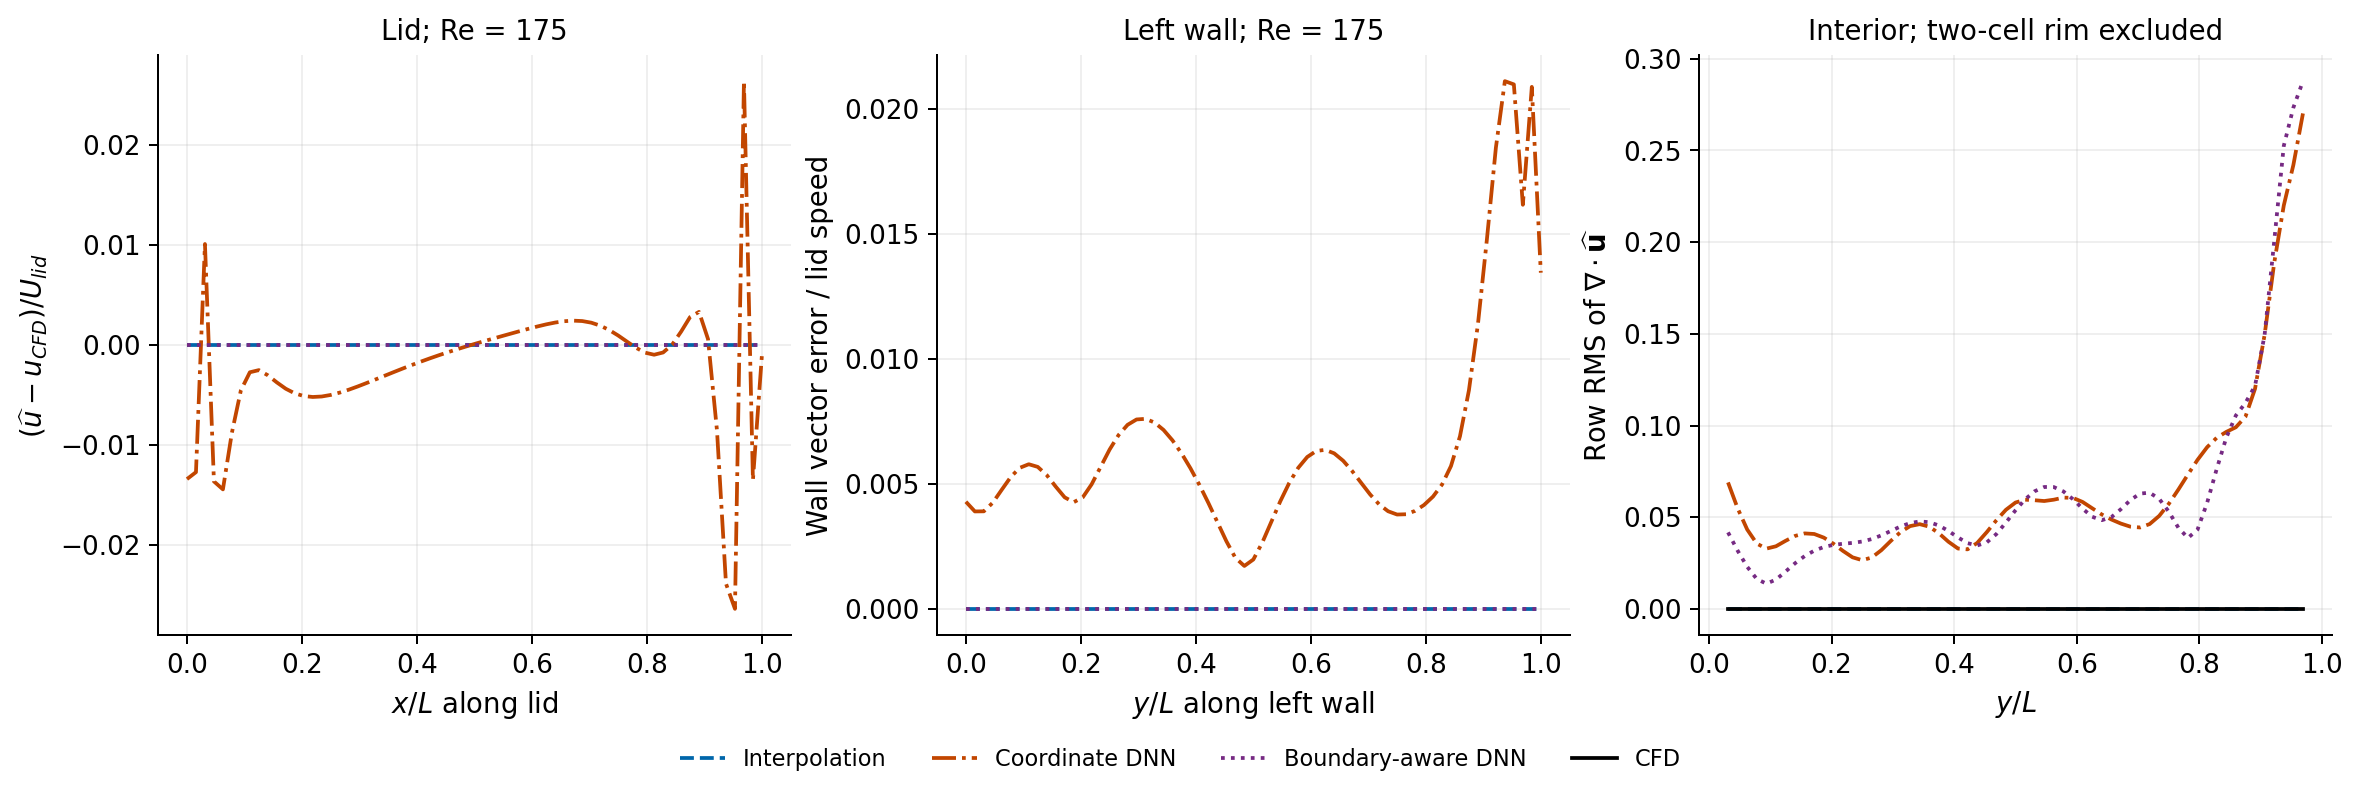

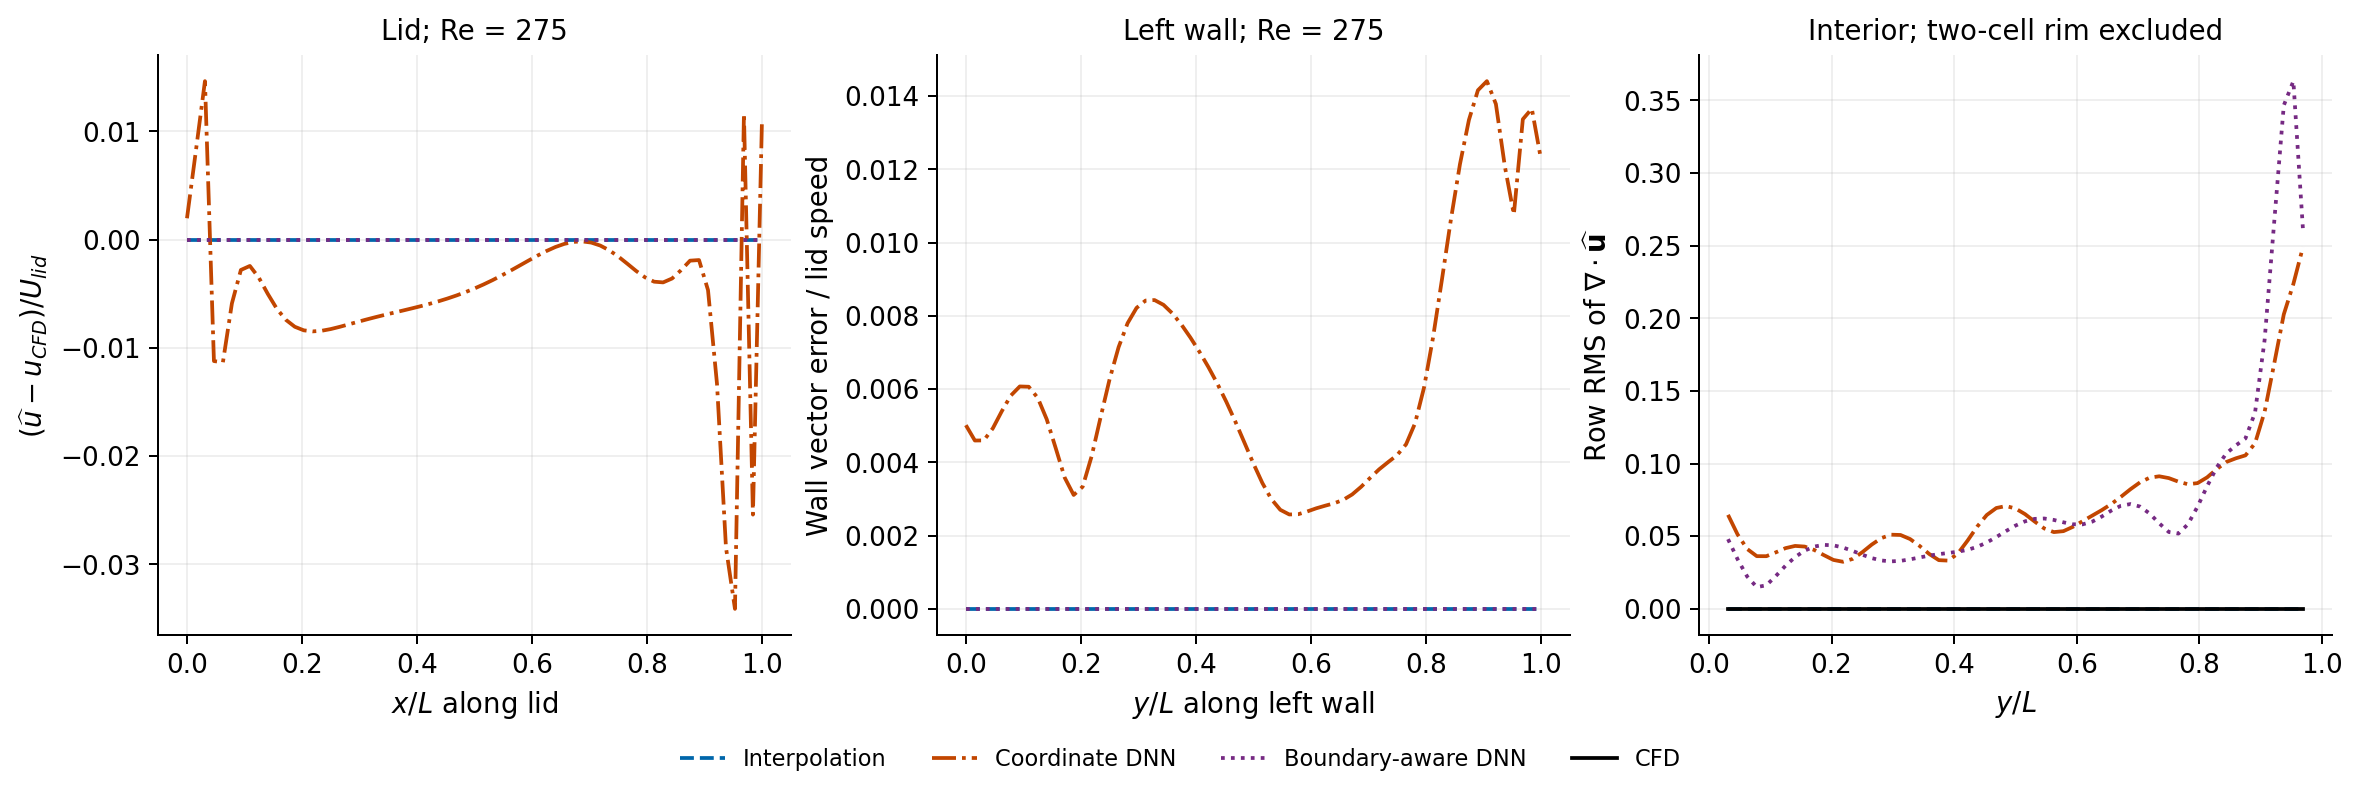

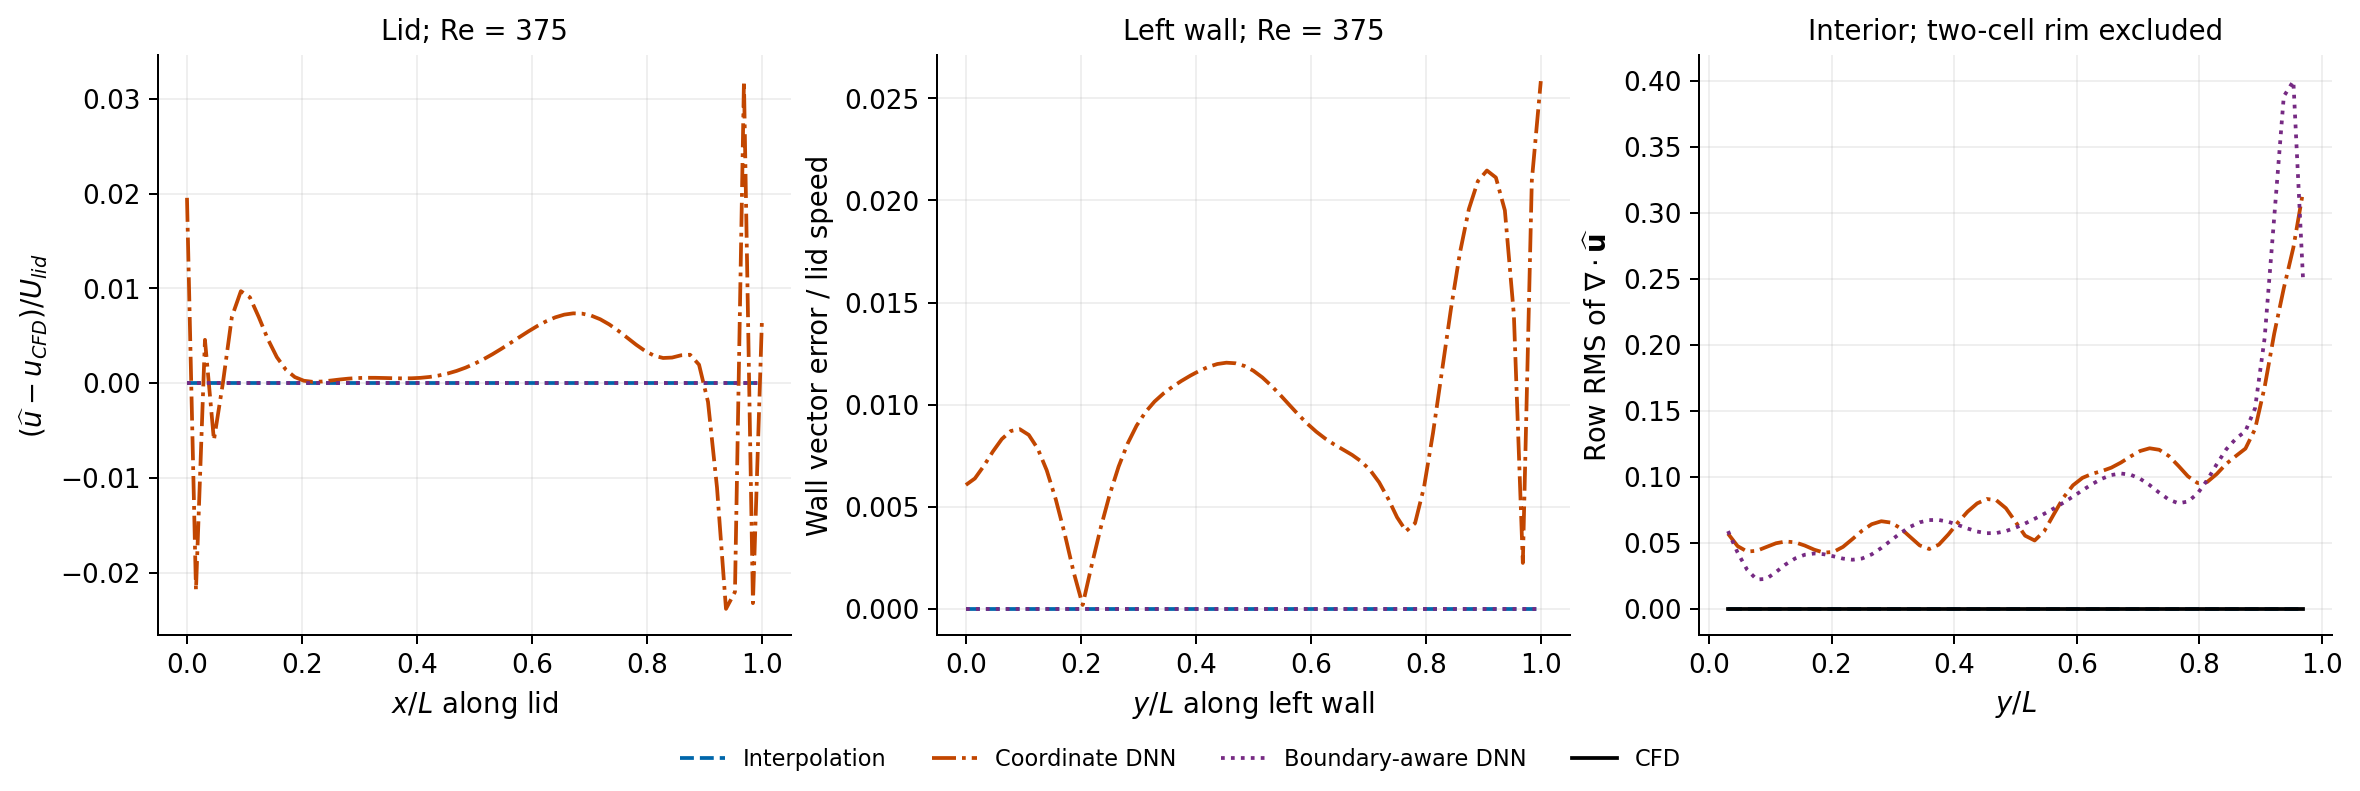

Retained outputs: /scratch3/workspace/roohie_umass_edu-flowml-ghia-highre-20261115/week04-lab2-qa-20261120/repo/results/week04_lab2
All test cases: [175.0, 275.0, 375.0]


In [13]:
for index, predictions in test_predictions.items():
    fig = plot_wall_diagnostics(data, index, predictions)
    save_figure(fig, OUT, f"wall_diagnostics_re{data['Re'][index]:g}"); plt.show()
print("Retained outputs:", OUT.resolve())
print("All test cases:", data["Re"][test].tolist())

## Required analysis

The original five questions remain mandatory:

1. Which scalar method is best on blind cases?
2. Does ensemble spread correlate with actual DNN error?
3. Why is the flattened grid not 46,475 independent flow cases?
4. Compare coordinate-DNN field error with field interpolation.
5. Report wall error, divergence, and both centerlines for one blind case.

### Engineering experiments and deliverables

6. **Data split:** list the fit, validation and test Re values. Explain why choosing
   epochs from the test error would invalidate the test. Reproduce the two validation
   loss curves and state the selected optimizer stage and iteration.
7. **Architecture:** compare two and four hidden layers at a roughly matched parameter
   count. Keep seeds, case split, point sampler and optimizer budgets fixed. Choose
   using validation only; report training time, parameters, and physical profiles.
8. **Activation:** compare tanh with sigmoid or ReLU on validation fields. Explain
   how a piecewise-linear field affects numerical derivatives. Do not use a smoother
   plotting interpolation to conceal derivative error.
9. **Boundary knowledge:** compare the raw and boundary-aware nets using the same
   training settings. Tabulate wall maximum error and interior divergence RMS. Mark
   the same speed contours and discuss any remaining shifted or missing circulation.
10. **Optimizer and budget:** set `FIELD_LBFGS_STEPS=0` to isolate Adam. Compare with
    the hybrid at equal elapsed time as an additional experiment, because equal
    iterations do not imply equal cost. Use validation results for the comparison.
11. **Sampling:** change `TRAIN_STRIDE` from 2 to 1 or 4. Record the actual point count,
    time, wall-adjacent coverage and validation profile error. The number of independent
    Reynolds cases remains unchanged.
12. **Report:** submit one concise comparison table and the scalar trends, one common-
    scale field/error figure, signed profiles, and wall/divergence curves. Discuss a
    win and a loss of each model. Retain CSV/NPZ outputs so another student can replot
    without retraining. Keep a newly chosen independent case for final confirmation
    if you adapt the model after examining these public test cases.

## 12. Why continue to Lab 3?

If the coordinate DNN still has larger error than interpolation, keep that result.
The model is learning the parameter dependence, wall gradients and spatial structure
at once. Exact wall values do not enforce interior incompressibility or momentum
balance. These limitations motivate a different representation, rather than a
promise that more layers will always win.

[Lab 3](W4_Lab3_DeepONet_Cavity_Student.ipynb) learns coefficients of a POD field
basis built from CFD. It can use the coherent spatial patterns already present in
the training snapshots. Its selection stage fits seven cases and validates Re = 225;
after selection it rebuilds the basis and refits on all eight development cases.
This Lab 2 keeps six fitting cases and two validation cases. Both exclude public
test Re = 175, 275, 375 from fitting, but their final training information differs.
Do not interpret cross-lab errors as a matched-information architecture contest.
For that experiment, rerun both methods with exactly the same split and budget.

## Article-output contract

<!-- MIE690A article-aligned validation v3 -->

**Role:** Figure 9: CFD/MLP blind-case fields and centerlines.

All manuscript-facing figures must be generated from retained numerical/model outputs through the documented notebook or shared helper, saved under `results/`, and accompanied by machine-readable metrics. Do not redraw curves by eye or substitute a screenshot for a solver-to-reference comparison. The complete ownership table and exact output filenames are in [`ARTICLE_FIGURE_MAP.md`](../../ARTICLE_FIGURE_MAP.md).

## Optional continuation: all seven Ghia Reynolds numbers

Continue with [Lab 5: seven-Re CFD coverage and qualification](../week04/W4_Lab5_All_Re_Ghia_Validation.ipynb). [Lab 6](../week04/W4_Lab6_Ghia_Profile_Optimizer_Depth.ipynb) fits Ghia centreline samples with matched optimizer/depth comparisons; [Lab 7](../week04/W4_Lab7_High_Re_CFD_Ghia.ipynb) qualifies our high-Re full fields before [Lab 8](../week04/W4_Lab8_High_Re_Field_DeepONet.ipynb) compares field predictions with interpolation. All seven Ghia Reynolds numbers have retained CFD, with mesh/steady limits reported in the corresponding study. [Profile evidence](../../results/cavity_ghia_allre/README.md) · [Field evidence](../../results/cavity_highre_ghia/README.md).